# TopK SAE activation and revival diagnostics
Analyze the completed strong-AuxK trial using a frozen **last checkpoint**. Identify features that never become positive on training inputs versus features suppressed by TopK competition. This is a checkpoint snapshot, not a reconstruction of historical training gradients. No training weights, counters, or source artifacts are modified; test data is not read.

In [1]:
from pathlib import Path
import sys, json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/mas_sae').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from mas_sae.sae.sparse_autoencoder import SparseAutoencoder
from mas_sae.sae.dataloader import ActivationDataset

TRIAL = ROOT / 'results/sae/musique/tuning/layer_25/20261022T192642968946Z-635354750790/trials/trial_0001'
BATCH_SIZE = 256
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
config = json.loads((TRIAL / 'config.json').read_text())
history = json.loads((TRIAL / 'history.json').read_text())
state = torch.load(TRIAL / 'checkpoints/last_checkpoint.pt', map_location='cpu', weights_only=True)
model = SparseAutoencoder(config['input_dim'], config['hidden_dim'], config['latent_dim'],
                          sparsity_mode=config['sparsity_mode'], top_k=config['top_k']).to(DEVICE)
model.load_state_dict(state['model'])
model.eval()
seen = state['training_examples_seen']
window = config['aux_dead_window_examples']
assert seen >= window, 'Checkpoint has not completed the AuxK warmup.'
eligible = (seen - state['last_fired_example']) >= window
activation_dir = ROOT / 'data/activations' / config['activation_run_name'] / f"layer_{config['layer']:02d}"
dataset = ActivationDataset('train', activation_dir)
print(f"Epoch {len(state['history'])}; AuxK={config['aux_coefficient']}; k={model.top_k}; device={DEVICE}")
print(f"Training examples: {len(dataset):,}; eligible at checkpoint: {eligible.float().mean():.1%}")

Epoch 83; AuxK=0.0625; k=64; device=cuda
Training examples: 31,872; eligible at checkpoint: 69.5%


## Training trajectory
Dictionary usage is one minus the fraction never firing in that epoch/split. Training epoch metrics use changing weights; the scan below freezes weights. Auxiliary eligibility is averaged during training, whereas the scan holds the checkpoint eligibility mask fixed.

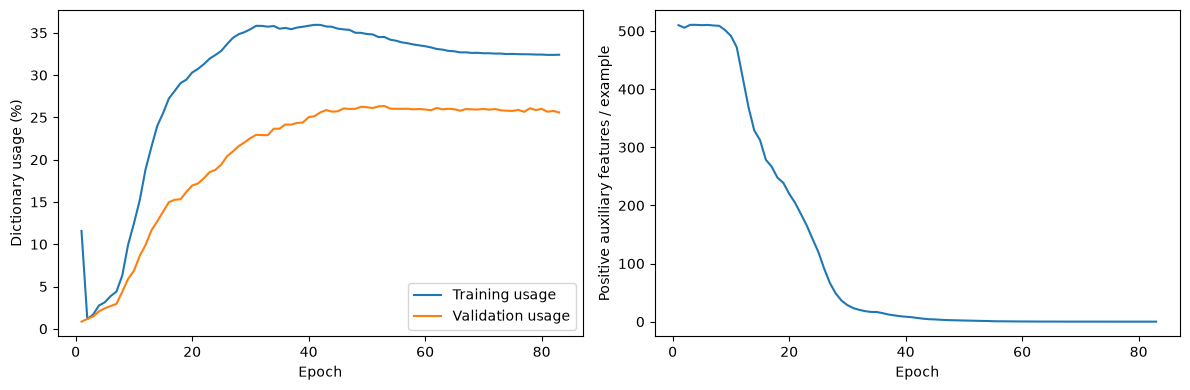

In [2]:
trajectory = pd.DataFrame(history['history'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, label in [('train_inactive_feature_fraction', 'Training usage'), ('val_inactive_feature_fraction', 'Validation usage')]:
    axes[0].plot(trajectory.epoch, 100 * (1 - trajectory[column]), label=label)
axes[0].set(xlabel='Epoch', ylabel='Dictionary usage (%)')
axes[0].legend()
aux = pd.DataFrame(trajectory.train_auxiliary.tolist())
axes[1].plot(trajectory.epoch, aux.mean_positive_features)
axes[1].set(xlabel='Epoch', ylabel='Positive auxiliary features / example')
plt.tight_layout()
plt.show()

In [3]:
width = model.latent_dim
positive_counts = torch.zeros(width, dtype=torch.long, device=DEVICE)
main_counts = torch.zeros_like(positive_counts)
aux_counts = torch.zeros_like(positive_counts)
max_scores = torch.full((width,), -torch.inf, device=DEVICE)
eligible_device = eligible.to(DEVICE)
k_aux = min(config['aux_k'], int(eligible.sum()))

with torch.inference_mode():
    for batch in torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False):
        batch = batch.to(DEVICE)
        # Use the model's normalization and encoder; inspect scores before ReLU.
        scores = model.encoder_layer[0](batch / model.input_scale)
        positive = scores.relu()
        main = model.select_topk(positive, model.top_k)
        positive_counts += (positive > 0).sum(0)
        main_counts += (main > 0).sum(0)
        max_scores = torch.maximum(max_scores, scores.amax(0))
        if k_aux:
            auxiliary = model.select_topk(positive.masked_fill(~eligible_device, -torch.inf), k_aux)
            aux_counts += (auxiliary > 0).sum(0)

features = pd.DataFrame({
    'feature_id': range(width),
    'eligible_at_checkpoint': eligible.numpy(),
    'positive_count': positive_counts.cpu().numpy(),
    'main_count': main_counts.cpu().numpy(),
    'auxiliary_count_fixed_mask': aux_counts.cpu().numpy(),
    'max_encoder_score': max_scores.cpu().numpy(),
})
for name in ['positive', 'main']:
    features[f'{name}_frequency'] = features[f'{name}_count'] / len(dataset)
features['category'] = 'Main-path active'
features.loc[(features.main_count == 0) & (features.positive_count > 0), 'category'] = 'Positive but never wins main TopK'
features.loc[features.positive_count == 0, 'category'] = 'Never positive on scanned training data'
print('Full training scan complete.')

Full training scan complete.


,eligible_at_checkpoint,category,features,percent_of_dictionary
0,False,Main-path active,3934,30.524519
1,False,Positive but never wins main TopK,3,0.023277
2,True,Main-path active,240,1.862197
3,True,Never positive on scanned training data,8658,67.178771
4,True,Positive but never wins main TopK,53,0.411235


Eligible features never positive: 96.7%
Distinct eligible features receiving positive auxiliary activations: 293
Main-path coverage: 32.4%


positive_frequency            \
                                                    median       max   
category                                                               
Main-path active                                  0.002102  1.000000   
Never positive on scanned training data           0.000000  0.000000   
Positive but never wins main TopK                 0.000188  0.001788   

                                        main_frequency      max_encoder_score  \
                                                median  max            median   
category                                                                        
Main-path active                              0.001224  1.0          3.689571   
Never positive on scanned training data       0.000000  0.0         -0.196850   
Positive but never wins main TopK             0.000000  0.0          0.102877   

                                                    
                                               max  
category                                            
Main-path active                         50.443417  
Never positive on scanned training data  -0.000072  
Positive but never wins main TopK         0.223415

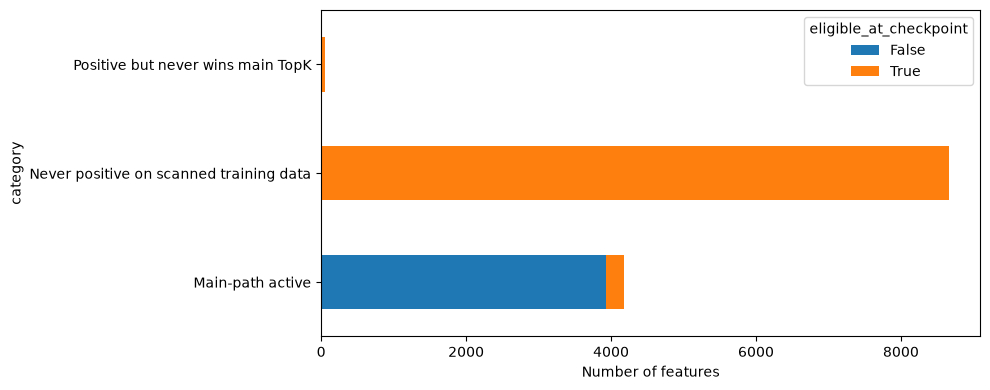

In [4]:
summary = features.groupby(['eligible_at_checkpoint', 'category']).size().rename('features').reset_index()
summary['percent_of_dictionary'] = 100 * summary.features / width
display(summary)
inactive = features[features.eligible_at_checkpoint]
if len(inactive):
    print(f"Eligible features never positive: {(inactive.positive_count == 0).mean():.1%}")
    print(f"Distinct eligible features receiving positive auxiliary activations: {(inactive.auxiliary_count_fixed_mask > 0).sum():,}")
print(f"Main-path coverage: {(features.main_count > 0).mean():.1%}")
display(features.groupby('category')[['positive_frequency', 'main_frequency', 'max_encoder_score']].agg(['median', 'max']))
features.groupby(['category', 'eligible_at_checkpoint']).size().unstack(fill_value=0).plot.barh(stacked=True, figsize=(10, 4))
plt.xlabel('Number of features')
plt.tight_layout()
plt.show()

## Interpretation and experiment decision
- A large **never-positive, eligible** group supports investigating ReLU-blocked revival. Zero activation blocks the direct encoder/decoder learning signal for those examples. It does not prove features could never activate on other data or after parameter updates.
- A large **positive but never wins main TopK** group points toward competition rather than an always-zero activation barrier.
- The auxiliary scan uses fixed checkpoint eligibility. Training updates this mask after every batch, so these auxiliary counts are diagnostic rather than a replay of training.
- Resampling is not implemented here. If justified, compare the same AuxK setup with versus without conservative resampling, resetting affected optimizer state and activity counters. Preserve checkpoints after recovery and track replaced feature IDs, repeated firing, validation coverage, and selective causal effects across seeds.
- Increased coverage alone does not establish causal usefulness. Use the existing feature-selection and causal-replay pipelines with matched intervention magnitudes.

In [5]:
# Optional: export the per-feature diagnostic separately from training artifacts.
EXPORT = False
if EXPORT:
    output_dir = ROOT / 'reports/tables/sae_top_k_analysis' / TRIAL.parent.parent.name / TRIAL.name
    output_dir.mkdir(parents=True, exist_ok=True)
    features.to_csv(output_dir / 'feature_activation_diagnostics.csv', index=False)
    summary.to_csv(output_dir / 'feature_activation_summary.csv', index=False)
    print(output_dir)

## Paired resampling continuation
Run from the repository root:
```bash
PYTHONPATH=src python scripts/experiment_sae_resampling.py --config configs/sae_hp_tuning/layer_25_resampling.yaml --dry-run
```
Remove `--dry-run` to train. Outputs go to a new directory; existing output directories are refused. Both branches use a constant inherited learning rate and fixed continuation budget. The source run is untouched.

Neuron resampling is motivated by [Bricken et al. (2023)](https://transformer-circuits.pub/2023/monosemantic-features/index.html). Residual directions, a 512-feature budget, and training-quantile encoder bias calibration are experimental adaptations. No causal improvement is assumed.


In [ ]:
experiment_dir = ROOT / 'results/sae/musique/resampling/layer_25/aux00625_pilot'
comparison = []
for path in sorted(experiment_dir.glob('seed_*/*/history.json')):
    for row in json.loads(path.read_text()):
        comparison.append({
            'seed': path.parent.parent.name, 'branch': path.parent.name,
            'epoch': row['epoch'], 'train_coverage': row['frozen_train_coverage'],
            'validation_coverage': 1 - row['validation']['inactive_feature_fraction'],
            'displaced': row['displaced_initially_active'],
            'replacement_main_active': row['replacement_main_active'],
            'replacement_validation_active': row['replacement_validation_active'],
            'replacement_repeated': row['replacement_repeated_10_examples'],
        })
if comparison:
    comparison = pd.DataFrame(comparison)
    display(comparison.groupby(['seed', 'branch']).tail(1))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for (seed, branch), group in comparison.groupby(['seed', 'branch']):
        for ax, metric in zip(axes, ['validation_coverage', 'replacement_repeated', 'displaced']):
            ax.plot(group.epoch, group[metric], label=f'{seed}/{branch}')
            ax.set(xlabel='Additional epoch', ylabel=metric)
    axes[0].legend()
    plt.tight_layout()
    plt.show()
else:
    print('No continuation histories yet. Run the experiment command above first.')


## Initialization and warmup comparison
Run the five-branch continuation from the repository root:
```bash
PYTHONPATH=src python scripts/experiment_sae_resampling.py --config configs/sae_hp_tuning/layer_25_resampling_comparison.yaml --dry-run
```
Remove `--dry-run` to train. Existing pilot results are preserved in their original directory.

All treatments replace the same source feature IDs per seed. Controls track those IDs without changing them. Seeds vary continuation order and replacement sampling, not the source dictionary's original training seed. Bricken initialization uses input directions, squared per-input reconstruction-loss sampling, and zero encoder biases; the residual strategy uses residual directions and calibrated biases. Our TopK/AuxK, dataset, candidate rule, RMS scaling, sampling without replacement, retained shared Adam steps, and warmup settings are adaptations. See [Bricken et al. (2023)](https://transformer-circuits.pub/2023/monosemantic-features/index.html).

Compare `warmup_control - control` for the learning-rate effect, `residual_warmup - residual` for warmup conditional on residual resampling, and `bricken_warmup - residual_warmup` for the initialization recipe. The last comparison changes direction, bias, live-feature scale reference, and sampling together; it does not isolate those ingredients individually.

In [ ]:
comparison_dir = ROOT / 'results/sae/musique/resampling/layer_25/aux00625_warmup_comparison'
records = []
for path in sorted(comparison_dir.glob('seed_*/*/history.json')):
    immediate_path = path.parent / 'post_intervention_metrics.json'
    snapshots = ([{'epoch': 0, **json.loads(immediate_path.read_text())}]
                 if immediate_path.exists() else []) + json.loads(path.read_text())
    for row in snapshots:
        records.append({
            'seed': path.parent.parent.name, 'branch': path.parent.name, 'epoch': row['epoch'],
            'validation_coverage': 100 * (1 - row['validation']['inactive_feature_fraction']),
            'validation_variance_explained': 100 * row['validation']['variance_explained'],
            'net_active_gain': row['net_active_gain'],
            'tracked_main_active': row['tracked_main_active'],
            'tracked_validation_active': row['tracked_validation_active'],
            'tracked_validation_repeated': row['tracked_validation_repeated_10_examples'],
            'displaced': row['displaced_initially_active'],
        })
if records:
    revival_comparison = pd.DataFrame(records)
    display(revival_comparison.groupby(['seed', 'branch']).tail(1))
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    metrics = ['tracked_main_active', 'tracked_validation_active', 'tracked_validation_repeated',
               'net_active_gain', 'validation_coverage', 'validation_variance_explained']
    for (seed, branch), group in revival_comparison.groupby(['seed', 'branch']):
        for ax, metric in zip(axes.flat, metrics):
            ax.plot(group.epoch, group[metric], label=f'{seed}/{branch}')
            ax.set(xlabel='Additional epoch (0 = immediate)', ylabel=metric)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print('No five-branch comparison results yet.')

In [ ]:
# Paired final differences; these are descriptive, not significance tests.
if records:
    final = revival_comparison.sort_values('epoch').groupby(['seed', 'branch']).tail(1)
    outcomes = ['tracked_validation_repeated', 'net_active_gain', 'validation_coverage',
                'validation_variance_explained', 'displaced']
    contrasts = []
    for seed, frame in final.groupby('seed'):
        frame = frame.set_index('branch')
        for treatment, control in [('warmup_control', 'control'), ('residual', 'control'),
                                   ('residual_warmup', 'warmup_control'),
                                   ('residual_warmup', 'residual'),
                                   ('bricken_warmup', 'residual_warmup')]:
            if treatment in frame.index and control in frame.index:
                contrasts.append({'seed': seed, 'contrast': f'{treatment} minus {control}',
                                  **{key: frame.loc[treatment, key] - frame.loc[control, key]
                                     for key in outcomes}})
    display(pd.DataFrame(contrasts))
    fig, ax = plt.subplots(figsize=(10, 3))
    for path in sorted(comparison_dir.glob('seed_*/*/learning_rates.json')):
        rates = json.loads(path.read_text())['rates_per_update']
        ax.plot(range(1, len(rates) + 1), [rate[0] for rate in rates],
                label=f'{path.parent.parent.name}/{path.parent.name}')
    ax.set(xlabel='Optimizer update', ylabel='Applied learning rate')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()